# Freight Rate Prediction

**Goal:** predict `posted_rate` (USD) for 12,000 loads from Nov–Dec 2025, using 48,000 labelled loads from Jan–Oct 2025.

This notebook does the whole job, top to bottom:

1. **Exploratory data analysis**: structure of the CSVs, missing values, distributions, data-quality issues, time patterns
2. **Cleaning and feature engineering**
3. **Validation design**: a time-based split, because we are predicting the future
4. **Model comparison**: baselines, then four cheap model families (linear, boosted trees, bagged trees, nearest neighbours)
5. **Ensembling**: averaging models from different families (the regression version of voting)
6. **Evaluation of the chosen model**: error tables, predicted vs actual, residuals, error by price band
7. **Final training and submission files**, then the December chart from `score.py`

Runs in about 3 minutes on a laptop. Run all cells in order.

In [1]:
import itertools
import subprocess
import sys
import time
from pathlib import Path

import holidays
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA = Path("data")
FIG = Path("outputs/figures")
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

BLUE, ORANGE, AQUA, YELLOW, GRAY, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#b4b2a9", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRAY,
    "axes.grid": True, "grid.color": GRID, "axes.titlelocation": "left", "axes.titleweight": "bold",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": MUTED,
})

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, bbox_inches="tight", facecolor="white")

## 1. Exploratory data analysis

### 1.1 What is in the files

In [2]:
train_raw = pd.read_csv(DATA / "train_test.csv", parse_dates=["date"])
val_raw = pd.read_csv(DATA / "validation.csv", parse_dates=["date"])
template = pd.read_csv(DATA / "validation_predictions_template.csv")
december_template = pd.read_csv(DATA / "december_chart_inputs.csv")
december_template["predicted_rate"] = np.nan   # this notebook fills it in section 7; blank it so reruns start clean

for name, d in [("train_test.csv", train_raw), ("validation.csv", val_raw),
                ("validation_predictions_template.csv", template), ("december_chart_inputs.csv", december_template)]:
    print(f"{name:38s} {d.shape[0]:>6,} rows x {d.shape[1]:>2} columns")
print()
print("Training dates:  ", train_raw.date.min().date(), "to", train_raw.date.max().date())
print("Validation dates:", val_raw.date.min().date(), "to", val_raw.date.max().date())
train_raw.head()

train_test.csv                         48,000 rows x 14 columns
validation.csv                         12,000 rows x 13 columns
validation_predictions_template.csv    12,000 rows x  2 columns
december_chart_inputs.csv                  31 rows x  7 columns

Training dates:   2025-01-01 to 2025-10-31
Validation dates: 2025-11-01 to 2025-12-31


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.091,-76.789,38.169,-72.746,274.300,Dry Van,"30,658.000",2025-01-01,0.957,2.396,645.410
1,TR-000002,Richmond,Philadelphia,38.091,-76.789,39.223,-72.967,280.500,Reefer,"17,555.000",2025-01-01,0.976,2.434,679.970
2,TR-000003,Philadelphia,Green Bay,39.223,-72.967,44.303,-87.529,967.800,Dry Van,"31,721.000",2025-01-01,1.010,1.845,"1,802.540"
3,TR-000004,Hartford,Atlanta,39.553,-72.181,34.849,-86.289,965.400,Dry Van,"32,333.000",2025-01-01,0.945,1.877,"1,827.280"
4,TR-000005,Dallas,Nashville,31.830,-94.383,35.295,-88.089,541.900,Reefer,"35,183.000",2025-01-01,0.985,2.563,"1,380.280"


In [3]:
train_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   load_id       48000 non-null  str           
 1   pickup        48000 non-null  str           
 2   delivery      48000 non-null  str           
 3   pickup_lat    48000 non-null  float64       
 4   pickup_lon    48000 non-null  float64       
 5   delivery_lat  48000 non-null  float64       
 6   delivery_lon  48000 non-null  float64       
 7   distance      48000 non-null  float64       
 8   equipment     48000 non-null  str           
 9   weight        47700 non-null  float64       
 10  date          48000 non-null  datetime64[us]
 11  market_index  47626 non-null  float64       
 12  quote_signal  48000 non-null  float64       
 13  posted_rate   48000 non-null  float64       
dtypes: datetime64[us](1), float64(9), str(4)
memory usage: 5.1 MB


In [4]:
train_raw.describe().T

,count,mean,min,25%,50%,75%,max,std
pickup_lat,"48,000.000",35.648,28.358,31.987,35.295,39.411,44.303,4.315
pickup_lon,"48,000.000",-90.929,-121.698,-98.401,-88.089,-83.285,-69.500,13.482
delivery_lat,"48,000.000",35.641,28.358,31.987,35.295,39.411,44.303,4.317
delivery_lon,"48,000.000",-90.857,-121.698,-98.401,-87.529,-83.285,-69.500,13.477
distance,"48,000.000","1,135.857",70.000,550.400,953.300,"1,645.525","3,439.800",728.564
weight,"47,700.000","31,028.844","-47,500.000","25,800.000","31,436.500","37,018.000","47,500.000","9,391.441"
date,48000,2025-05-31 19:53:29.399999,2025-01-01 00:00:00,2025-03-18 00:00:00,2025-05-31 00:00:00,2025-08-15 00:00:00,2025-10-31 00:00:00,NaN
market_index,"47,626.000",1.083,0.676,0.950,1.056,1.220,1.468,0.168
quote_signal,"48,000.000",2.062,0.692,1.891,2.056,2.222,3.610,0.291
posted_rate,"48,000.000","2,373.981",57.220,"1,251.555","2,030.760","3,330.750","25,533.000","1,486.493"


In [5]:
val_raw.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.501,-92.654,31.804,-88.252,331.400,Flatbed,"19,958.000",2025-11-01,0.904,1.864
1,TE-000002,Savannah,Los Angeles,33.610,-82.300,28.566,-116.702,"2,406.200",Reefer,"34,114.000",2025-11-01,0.929,1.862
2,TE-000003,San Francisco,Raleigh,35.197,-121.698,35.374,-77.476,"2,846.600",Dry Van,"33,435.000",2025-11-01,0.881,1.955
3,TE-000004,Dayton,Los Angeles,39.872,-85.629,28.566,-116.702,"2,261.600",Dry Van,"25,392.000",2025-11-01,0.892,2.146
4,TE-000005,Memphis,San Antonio,35.568,-89.529,29.510,-98.401,800.400,Flatbed,NaN,2025-11-01,0.883,2.225


In [6]:
december_template.head()

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,NaN
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,NaN


**Observations**

- The training data covers **January–October 2025** and the loads to predict cover **November–December 2025**. We are forecasting future months, which decides how we must validate (section 3).
- `validation.csv` has the same features as training, minus `posted_rate`.
- `december_chart_inputs.csv` only has pickup, delivery, distance, equipment, weight and date. **It has no `market_index` and no `quote_signal`**, so we will need a way to fill them in.
- `weight` has a **negative minimum (−47,500)** and `posted_rate` ranges from $57 to $25,533. Both need a closer look.

### 1.2 Missing values, duplicates and categories

In [7]:
quality = pd.DataFrame({
    "missing_train": train_raw.isna().sum(),
    "missing_validation": val_raw.isna().sum().reindex(train_raw.columns),
})
print("Duplicate load_ids in train:", train_raw.load_id.duplicated().sum(),
      "| in validation:", val_raw.load_id.duplicated().sum())
print("Rates <= 0:", (train_raw.posted_rate <= 0).sum())
quality[quality.sum(axis=1) > 0]

Duplicate load_ids in train: 0 | in validation: 0
Rates <= 0: 0


,missing_train,missing_validation
weight,300,165.000
market_index,374,249.000


In [8]:
equipment = pd.concat([train_raw.equipment.value_counts().rename("train"),
                       val_raw.equipment.value_counts().rename("validation")], axis=1)
equipment["train_share"] = equipment.train / equipment.train.sum()
equipment

,train,validation,train_share
equipment,,,
Dry Van,27202,6780,0.567
Reefer,12045,3051,0.251
Flatbed,8753,2169,0.182


In [9]:
train_cities = set(train_raw.pickup) | set(train_raw.delivery)
val_cities = set(val_raw.pickup) | set(val_raw.delivery)
unseen_cities = sorted(val_cities - train_cities)
touches_unseen = val_raw.pickup.isin(unseen_cities) | val_raw.delivery.isin(unseen_cities)
train_lanes = set(zip(train_raw.pickup, train_raw.delivery))
val_lane_seen = [lane in train_lanes for lane in zip(val_raw.pickup, val_raw.delivery)]

print(f"Cities in train: {len(train_cities)}, in validation: {len(val_cities)}")
print(f"Cities in validation never seen in training ({len(unseen_cities)}): {unseen_cities}")
print(f"Validation loads touching an unseen city: {touches_unseen.sum():,} ({touches_unseen.mean():.1%})")
print(f"Validation loads on a lane never seen in training: {1 - np.mean(val_lane_seen):.1%}")
print(f"Coordinates per city (should be 1): {train_raw.groupby('pickup').pickup_lat.nunique().max()}")

Cities in train: 64, in validation: 72
Cities in validation never seen in training (8): ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
Validation loads touching an unseen city: 1,447 (12.1%)
Validation loads on a lane never seen in training: 12.2%
Coordinates per city (should be 1): 1


- Missing values are limited to `weight` (300 train / 165 validation) and `market_index` (374 / 249).
- No duplicate IDs and no zero or negative rates.
- **8 cities appear only in validation.** That is 12% of the loads we must predict, so the model must generalise through coordinates and distance rather than memorising cities or lanes.

### 1.3 What drives the rate

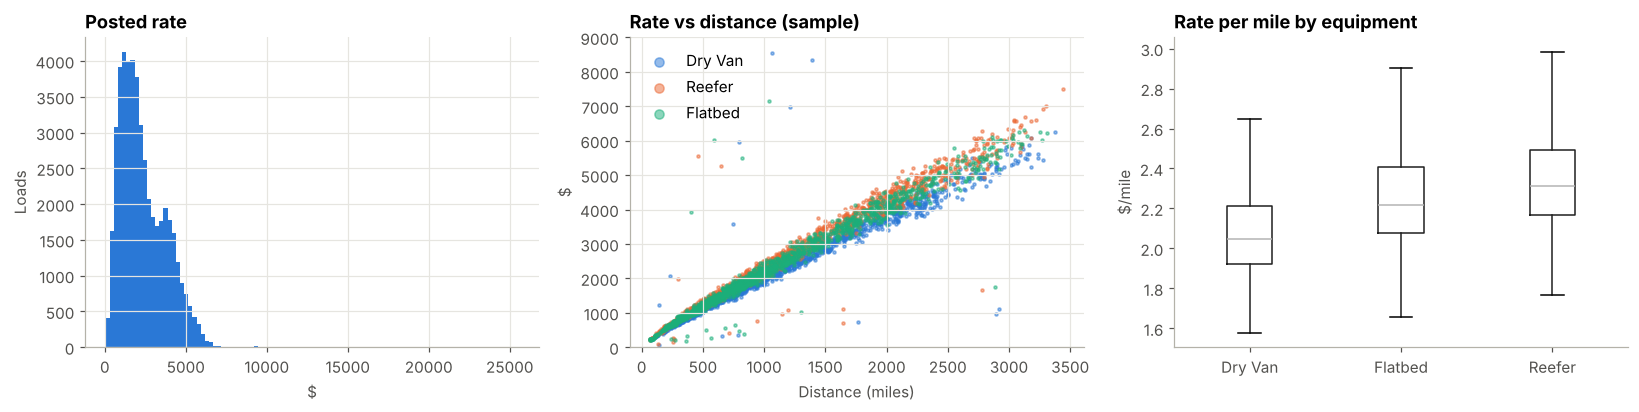

equipment
Dry Van   2.046
Flatbed   2.220
Reefer    2.312
Name: rate_per_mile, dtype: float64
distance
(69.999, 431.383]      2.547
(431.383, 688.2]       2.284
(688.2, 953.3]         2.167
(953.3, 1322.533]      2.092
(1322.533, 1967.917]   2.015
(1967.917, 3439.8]     1.914
Name: rate_per_mile, dtype: float64


In [10]:
t = train_raw.copy()
t["rate_per_mile"] = t.posted_rate / t.distance

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(t.posted_rate, bins=100, color=BLUE)
axes[0].set(title="Posted rate", xlabel="$", ylabel="Loads")
for eq, c in zip(["Dry Van", "Reefer", "Flatbed"], [BLUE, ORANGE, AQUA]):
    s = t[t.equipment == eq].sample(1500, random_state=SEED)
    axes[1].scatter(s.distance, s.posted_rate, s=4, alpha=0.5, color=c, label=eq)
axes[1].set(title="Rate vs distance (sample)", xlabel="Distance (miles)", ylabel="$", ylim=(0, 9000))
axes[1].legend(frameon=False, markerscale=3)
t.boxplot(column="rate_per_mile", by="equipment", ax=axes[2], showfliers=False, grid=False)
axes[2].set(title="Rate per mile by equipment", xlabel="", ylabel="$/mile")
fig.suptitle("")
savefig(fig, "eda_rate_drivers.png")
plt.show()

print(t.groupby("equipment").rate_per_mile.median().round(3))
print(t.groupby(pd.qcut(t.distance, 6), observed=True).rate_per_mile.median().round(3))

In [11]:
corr = t[["distance", "weight", "market_index", "quote_signal", "posted_rate", "rate_per_mile"]].corr()
corr[["posted_rate", "rate_per_mile"]].round(3)

,posted_rate,rate_per_mile
distance,0.909,-0.335
weight,0.035,0.075
market_index,0.034,0.083
quote_signal,-0.040,0.049
posted_rate,1.000,0.003
rate_per_mile,0.003,1.000


- **Distance dominates.** Rate is nearly linear in distance (correlation 0.91), and rate per mile falls on longer hauls (about $2.55 for the shortest sixth of loads, $1.91 for the longest).
- **Equipment matters.** Median rate per mile: Dry Van $2.05, Flatbed $2.22, Reefer $2.31.
- `weight`, `market_index` and `quote_signal` show almost no *row-level* correlation with rate per mile. That is misleading, as section 1.5 shows once distance and equipment effects are removed.
- A handful of loads have extreme rates per mile (up to $14). Next section.

### 1.4 Data-quality issues

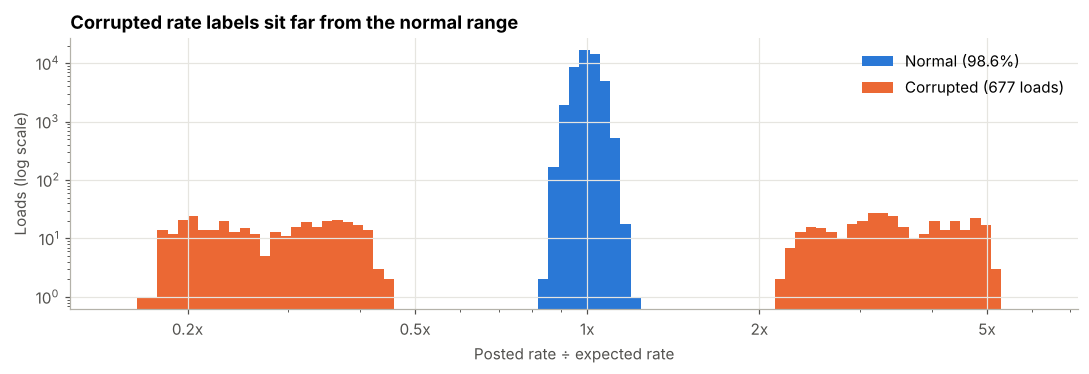

Ratio range of normal loads:    0.85 - 1.19
Ratio range of corrupted loads: 0.17 - 0.45 and 2.17 - 5.29
Corrupted loads per month: {1: 81, 2: 57, 3: 71, 4: 66, 5: 62, 6: 63, 7: 65, 8: 68, 9: 64, 10: 80}


In [12]:
# Expected log rate from distance, equipment and month; look at actual / expected
def expected_ratio(d):
    X = np.column_stack([np.ones(len(d)), np.log(d.distance), d.equipment.eq("Reefer"), d.equipment.eq("Flatbed"),
                         pd.get_dummies(d.date.dt.month, drop_first=True).to_numpy(float)]).astype(float)
    y = np.log(d.posted_rate.to_numpy())
    keep = np.ones(len(d), bool)
    for _ in range(2):                       # refit once without gross outliers
        beta, *_ = np.linalg.lstsq(X[keep], y[keep], rcond=None)
        ratio = np.exp(y - X @ beta)
        keep = (ratio > 0.6) & (ratio < 1.7)
    return pd.Series(ratio, index=d.index)

t["ratio"] = expected_ratio(t)
fig, ax = plt.subplots(figsize=(10, 3.5))
bins = np.logspace(np.log10(0.15), np.log10(6), 90)
ok = t.ratio.between(0.6, 1.7)
ax.hist(t.ratio[ok], bins=bins, color=BLUE, label=f"Normal ({ok.mean():.1%})")
ax.hist(t.ratio[~ok], bins=bins, color=ORANGE, label=f"Corrupted ({(~ok).sum()} loads)")
ax.set(xscale="log", yscale="log", xlabel="Posted rate ÷ expected rate", ylabel="Loads (log scale)",
       title="Corrupted rate labels sit far from the normal range")
ax.set_xticks([0.2, 0.5, 1, 2, 5], ["0.2x", "0.5x", "1x", "2x", "5x"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.legend(frameon=False)
savefig(fig, "label_outliers.png")
plt.show()

print("Ratio range of normal loads:   ", t.ratio[ok].min().round(2), "-", t.ratio[ok].max().round(2))
print("Ratio range of corrupted loads:", t.ratio[~ok & (t.ratio < 1)].min().round(2), "-", t.ratio[~ok & (t.ratio < 1)].max().round(2),
      "and", t.ratio[~ok & (t.ratio > 1)].min().round(2), "-", t.ratio[~ok & (t.ratio > 1)].max().round(2))
print("Corrupted loads per month:", t[~ok].date.dt.month.value_counts().sort_index().to_dict())

In [13]:
neg = t[t.weight < 0]
print(f"Negative weights: {len(neg)} in train, {(val_raw.weight < 0).sum()} in validation")
print("abs(negative weights) look like normal weights:")
print(pd.DataFrame({"abs(negative)": neg.weight.abs().describe(), "positive": t.weight[t.weight > 0].describe()}).round(0).T)
print(f"\nLoads at exactly 47,500 lb (a cap): {(t.weight == 47_500).sum():,}; max weight: {t.weight.max():,.0f}")

Negative weights: 292 in train, 145 in validation
abs(negative weights) look like normal weights:
                   count       mean       std       min        25%        50%        75%        max
abs(negative)    292.000 31,724.000 8,263.000 5,000.000 25,928.000 31,822.000 37,284.000 47,500.000
positive      47,408.000 31,415.000 7,995.000 5,000.000 25,922.000 31,494.000 37,063.000 47,500.000

Loads at exactly 47,500 lb (a cap): 1,191; max weight: 47,500


In [14]:
def haversine_miles(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(h))

t["straight_miles"] = haversine_miles(t.pickup_lat, t.pickup_lon, t.delivery_lat, t.delivery_lon)
t["circuity"] = t.distance / t.straight_miles
print(t.circuity.describe().round(3))
print("\nLoads with road distance > 1.5x straight line, by distance:")
print(t[t.circuity > 1.5].distance.describe().round(0))

count   48,000.000
mean         1.195
std          0.144
min          1.058
25%          1.165
50%          1.182
75%          1.205
max          9.635
Name: circuity, dtype: float64

Loads with road distance > 1.5x straight line, by distance:
count   214.000
mean     97.000
std      26.000
min      70.000
25%      79.000
50%      89.000
75%     108.000
max     224.000
Name: distance, dtype: float64


| Issue | Size | Decision |
|---|---|---|
| **Corrupted `posted_rate`**: 0.17–0.45× or 2.2–5.3× the expected rate, with an empty gap separating them from normal loads (0.85–1.2×) | 677 loads (1.4%), spread evenly across months | Remove from **training only**. Thresholds 0.6× / 1.7× sit in the gap, so the result is not sensitive to them. |
| **Negative weight**: magnitudes match normal weights, so these are sign errors | 292 train, present in validation | Absolute value, plus a flag column |
| **Missing weight** | 300 / 165 | Equipment median, plus a flag column |
| **Weight capped at 47,500 lb** | 1,191 loads | Keep; flag capped rows |
| **Missing `market_index`** | 374 / 249 | Same-day mean (see 1.5: it is a daily value) |
| Road distance > 1.5× straight line | 214 loads | Not an error: all short hauls, where roads are naturally less direct. Kept as a `circuity` feature. |

### 1.5 Time patterns: market index, trend and quarter-end

market_index std overall: 0.168   average std within a single day: 0.025
-> market_index is essentially one value per day (a daily market level).
Autocorrelation of daily market_index by lag (days): {1: np.float64(0.93), 3: np.float64(0.64), 7: np.float64(0.97), 14: np.float64(0.92)} -> weekly cycle


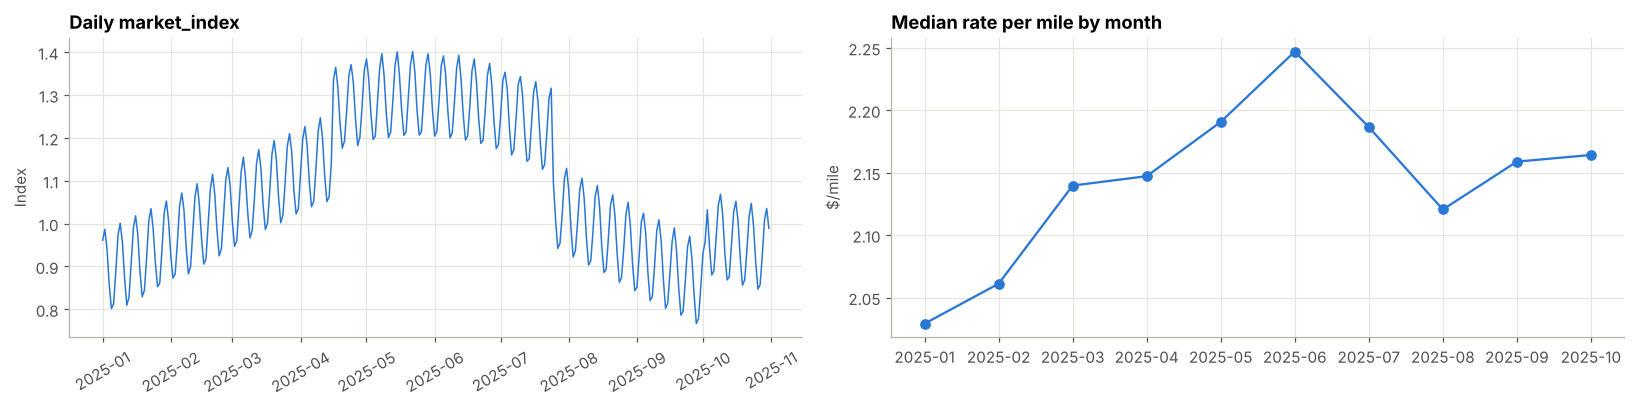

date,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10
market_index,0.927,0.996,1.073,1.207,1.301,1.280,1.201,0.981,0.893,0.957
rate_per_mile,2.029,2.061,2.140,2.147,2.191,2.247,2.187,2.121,2.159,2.164


In [15]:
within_day = t.groupby("date").market_index.std().mean()
print(f"market_index std overall: {t.market_index.std():.3f}   average std within a single day: {within_day:.3f}")
print("-> market_index is essentially one value per day (a daily market level).")

daily = t.groupby("date").agg(market_index=("market_index", "mean"), rate_per_mile=("rate_per_mile", "median"))
lags = {lag: daily.market_index.autocorr(lag) for lag in [1, 3, 7, 14]}
print("Autocorrelation of daily market_index by lag (days):", {k: round(v, 2) for k, v in lags.items()}, "-> weekly cycle")

fig, ax1 = plt.subplots(1, 2, figsize=(15, 3.8))
ax1[0].plot(daily.index, daily.market_index, color=BLUE, lw=1)
ax1[0].set(title="Daily market_index", ylabel="Index")
ax1[0].tick_params(axis="x", rotation=30)
monthly = t[ok].groupby(t.date.dt.to_period("M")).agg(market_index=("market_index", "mean"), rate_per_mile=("rate_per_mile", "median"))
ax1[1].plot(monthly.index.astype(str), monthly.rate_per_mile, color=BLUE, marker="o")
ax1[1].set(title="Median rate per mile by month", ylabel="$/mile")
savefig(fig, "eda_time.png")
plt.show()
monthly.T

In [16]:
# Remove distance/equipment/weight effects, then look at what is left over time
c = t[ok].copy()
c["weight"] = c.weight.abs()
c = c.dropna(subset=["weight", "market_index"])
ld = np.log(c.distance)
months = (c.date - pd.Timestamp("2025-01-01")).dt.days / 30.4
base_X = np.column_stack([np.ones(len(c)), ld, ld**2, c.equipment.eq("Reefer"), c.equipment.eq("Flatbed"), c.weight / 1e4]).astype(float)

def fit_resid(X):
    beta, *_ = np.linalg.lstsq(X, np.log(c.posted_rate), rcond=None)
    return np.log(c.posted_rate) - X @ beta, beta

r_mi, b_mi = fit_resid(np.column_stack([base_X, c.market_index]))
r_mi_t, b_mi_t = fit_resid(np.column_stack([base_X, c.market_index, months]))
print(f"Effect of +1 market_index: {np.expm1(b_mi[-1]):.1%} on rate")
print(f"Upward trend beyond market_index: {np.expm1(b_mi_t[-1]):.2%} per month")
print("\nAverage residual by month after market_index + trend (%):")
print((r_mi_t.groupby(c.date.dt.month).mean() * 100).round(2).to_dict())

Effect of +1 market_index: 14.0% on rate
Upward trend beyond market_index: 0.64% per month

Average residual by month after market_index + trend (%):
{1: -0.28, 2: -0.49, 3: 1.41, 4: -0.7, 5: -0.39, 6: 1.66, 7: -0.72, 8: -1.21, 9: 0.96, 10: -0.3}


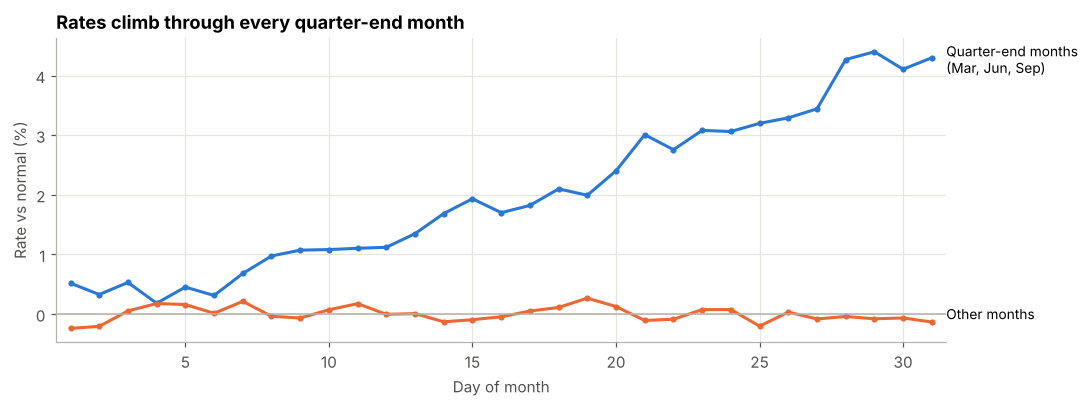

Residual (%) by week of month, each quarter-end month separately:
date  (0, 7]  (7, 14]  (14, 21]  (21, 25]  (25, 31]
date                                               
3      0.060    0.650     1.590     2.570     3.180
6      0.090    1.060     2.020     2.840     3.730
9     -0.470    0.300     1.180     2.050     3.340


In [17]:
c["resid_pct"] = (np.exp(r_mi_t) - 1) * 100
c["quarter_end_month"] = c.date.dt.month.isin([3, 6, 9])
by_day = c.groupby(["quarter_end_month", c.date.dt.day]).resid_pct.mean().unstack(0)
by_day = by_day - by_day[False].mean()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(by_day.index, by_day[True], color=BLUE, marker="o", ms=3, lw=2)
ax.plot(by_day.index, by_day[False], color=ORANGE, marker="o", ms=3, lw=2)
ax.text(31.5, by_day[True].iloc[-3:].mean(), "Quarter-end months\n(Mar, Jun, Sep)", va="center", fontsize=9)
ax.text(31.5, 0, "Other months", va="center", fontsize=9)
ax.axhline(0, color=GRAY, lw=1)
ax.set(xlim=(0.5, 31.5), xlabel="Day of month", ylabel="Rate vs normal (%)", title="Rates climb through every quarter-end month")
savefig(fig, "quarter_end_ramp.png")
plt.show()

seg = pd.cut(c.date.dt.day, [0, 7, 14, 21, 25, 31])
print("Residual (%) by week of month, each quarter-end month separately:")
print(c[c.quarter_end_month].groupby([c.date.dt.month, seg], observed=True).resid_pct.mean().unstack().round(2))

In [18]:
us_holidays = pd.to_datetime([d for d in holidays.US(years=2025)])
day_resid = c.groupby("date").resid_pct.mean()
print("Residual (%) on US holidays in the training period:")
print(day_resid.reindex(us_holidays[us_holidays <= "2025-10-31"]).round(2).dropna().to_dict())
print("\nResidual (%) by day of week (0=Mon):", c.groupby(c.date.dt.dayofweek).resid_pct.mean().round(2).to_dict())
print("Correlation of quote_signal with residual:", round(np.corrcoef(c.quote_signal, c.resid_pct)[0, 1], 3))

Residual (%) on US holidays in the training period:
{Timestamp('2025-01-01 00:00:00'): -0.26, Timestamp('2025-05-26 00:00:00'): 0.4, Timestamp('2025-06-19 00:00:00'): 1.87, Timestamp('2025-07-04 00:00:00'): -0.68, Timestamp('2025-09-01 00:00:00'): -0.24, Timestamp('2025-01-20 00:00:00'): -0.14, Timestamp('2025-02-17 00:00:00'): -0.34, Timestamp('2025-10-13 00:00:00'): 0.39}

Residual (%) by day of week (0=Mon): {0: 0.41, 1: 0.02, 2: -0.18, 3: -0.29, 4: -0.08, 5: 0.19, 6: 0.36}
Correlation of quote_signal with residual: 0.172


**EDA summary: what the model has to handle**

1. **Distance and equipment explain most of the rate.** The remaining variation is a few percent.
2. **`market_index` is a daily market level with a weekly cycle.** +1 index ≈ +15% rate. Row-level correlation hid this.
3. **Rates rise about 0.6% per month beyond the market index.** Tree models cannot extrapolate this into Nov–Dec on their own.
4. **Every quarter-end month (Mar, Jun, Sep), rates ramp from normal to about +4% by month end.** The pattern is nearly identical each quarter. **December is a quarter-end month.**
5. No holiday effect (Juneteenth looks high only because it falls inside the June quarter-end ramp). Day-of-week effects are under ±0.5%. `quote_signal` is weak on its own but has a real link once other effects are removed (correlation 0.17), so the models keep it.
6. 677 corrupted rate labels, sign-flipped weights and missing values need fixing, and 8 cities in validation are new.

## 2. Cleaning and feature engineering

Feature fixes apply to every dataset. Label-outlier removal applies to training rows only.

In [19]:
WEIGHT_CAP = 47_500

def daily_market_index(*frames):
    """Mean market_index per date across all loads given (features only, never labels)."""
    return pd.concat([f[["date", "market_index"]] for f in frames]).groupby("date").market_index.mean()

DAILY_MARKET = daily_market_index(train_raw, val_raw)

def clean(df):
    out = df.copy()
    out["weight_was_negative"] = (out.weight < 0).astype(int)
    out["weight"] = out.weight.abs()
    out["weight_missing"] = out.weight.isna().astype(int)
    out["weight"] = out.weight.fillna(out.groupby("equipment").weight.transform("median")).fillna(31_000)
    out["weight_capped"] = (out.weight >= WEIGHT_CAP).astype(int)
    if "market_index" not in out:
        out["market_index"] = np.nan
    out["market_index_missing"] = out.market_index.isna().astype(int)
    out["market_index"] = out.market_index.fillna(out.date.map(DAILY_MARKET))
    return out

def flag_label_outliers(df):
    return ~expected_ratio(df).between(0.6, 1.7)

train = clean(train_raw)
val = clean(val_raw)
train["label_outlier"] = flag_label_outliers(train)
print(f"Flagged {train.label_outlier.sum()} corrupted labels; remaining missing values:",
      int(train[["weight", "market_index"]].isna().sum().sum()), "(train)",
      int(val[["weight", "market_index"]].isna().sum().sum()), "(validation)")

Flagged 677 corrupted labels; remaining missing values: 0 (train) 0 (validation)


In [20]:
EQUIPMENT = ["Dry Van", "Reefer", "Flatbed"]
T0 = pd.Timestamp("2025-01-01")

def quarter_end_ramp(dates):
    """0 outside quarter-end months; inside Mar/Jun/Sep/Dec rises from 0 on day 1 to 1 on the last day."""
    qe = dates.dt.month.isin([3, 6, 9, 12]).to_numpy()
    frac = ((dates.dt.day - 1) / (dates.dt.days_in_month - 1)).to_numpy()
    return np.where(qe, frac, 0.0)

def base_features(df):
    f = pd.DataFrame(index=df.index)
    f["distance"] = df.distance
    f["log_distance"] = np.log(df.distance)
    f["straight_miles"] = haversine_miles(df.pickup_lat, df.pickup_lon, df.delivery_lat, df.delivery_lon)
    f["circuity"] = df.distance / f.straight_miles.clip(lower=1)
    for col in ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"]:
        f[col] = df[col]
    f["delta_lat"] = df.delivery_lat - df.pickup_lat
    f["delta_lon"] = df.delivery_lon - df.pickup_lon
    for eq in EQUIPMENT[1:]:
        f[f"equip_{eq}"] = (df.equipment == eq).astype(int)
    for col in ["weight", "weight_missing", "weight_capped", "market_index", "quote_signal"]:
        f[col] = df[col]
    f["day_of_week"] = df.date.dt.dayofweek
    f["quarter_end_ramp"] = quarter_end_ramp(df.date)
    return f


class TargetEncoder:
    """Smoothed mean log(rate per mile) per pickup, delivery, lane and lane+equipment.
    Training rows get out-of-fold values so no load sees its own rate. Unseen keys -> global mean."""
    KEYS = {"pickup_te": ["pickup"], "delivery_te": ["delivery"],
            "lane_te": ["pickup", "delivery"], "lane_eq_te": ["pickup", "delivery", "equipment"]}

    def __init__(self, smoothing=20, n_splits=5):
        self.smoothing, self.n_splits = smoothing, n_splits

    @staticmethod
    def _key(df, cols):
        return df[cols].astype(str).agg("|".join, axis=1)

    def _table(self, keys, y):
        g = y.groupby(keys).agg(["sum", "count"])
        return (g["sum"] + self.smoothing * self.prior) / (g["count"] + self.smoothing)

    def fit_transform(self, df, y):
        self.prior = float(y.mean())
        self.tables = {n: self._table(self._key(df, c), y) for n, c in self.KEYS.items()}
        out = pd.DataFrame(index=df.index, columns=list(self.KEYS), dtype=float)
        for tr, va in KFold(self.n_splits, shuffle=True, random_state=SEED).split(df):
            for n, c in self.KEYS.items():
                table = self._table(self._key(df.iloc[tr], c), y.iloc[tr])
                out.iloc[va, out.columns.get_loc(n)] = self._key(df.iloc[va], c).map(table).to_numpy()
        return out.fillna(self.prior)

    def transform(self, df):
        return pd.DataFrame({n: self._key(df, c).map(self.tables[n]) for n, c in self.KEYS.items()},
                            index=df.index).fillna(self.prior)

base_features(train).head()

,distance,log_distance,straight_miles,circuity,pickup_lat,pickup_lon,delivery_lat,delivery_lon,delta_lat,delta_lon,equip_Reefer,equip_Flatbed,weight,weight_missing,weight_capped,market_index,quote_signal,day_of_week,quarter_end_ramp
0,274.300,5.614,219.809,1.248,38.091,-76.789,38.169,-72.746,0.078,4.043,0,0,"30,658.000",0,0,0.957,2.396,2,0.000
1,280.500,5.637,220.526,1.272,38.091,-76.789,39.223,-72.967,1.132,3.822,1,0,"17,555.000",0,0,0.976,2.434,2,0.000
2,967.800,6.875,826.920,1.170,39.223,-72.967,44.303,-87.529,5.080,-14.562,0,0,"31,721.000",0,0,1.010,1.845,2,0.000
3,965.400,6.873,840.541,1.149,39.553,-72.181,34.849,-86.289,-4.704,-14.109,0,0,"32,333.000",0,0,0.945,1.877,2,0.000
4,541.900,6.295,434.163,1.248,31.830,-94.383,35.295,-88.089,3.465,6.294,1,0,"35,183.000",0,0,0.985,2.563,2,0.000


### The market-trend baseline

Tree models (LightGBM, Random Forest) and KNN can only predict values close to those they saw in training. Rates in Nov–Dec will sit above the training range because of the upward trend and the December quarter-end surge, so these models would systematically underpredict.

The fix is a small linear model in log space that captures the market-wide drivers:

`log(rate) ~ log(distance) + log(distance)² + equipment + weight + market_index + months_since_Jan + quarter_end_ramp`

Every model family below then learns the **remaining** part (the residual): lane, location and interaction effects. Final prediction = `exp(trend baseline + model residual prediction)`.

In [21]:
class MarketTrend:
    def _X(self, df):
        ld = np.log(df.distance.to_numpy())
        months = (df.date - T0).dt.days.to_numpy() / 30.4
        return np.column_stack([np.ones(len(df)), ld, ld**2,
                                (df.equipment == "Reefer").to_numpy(float), (df.equipment == "Flatbed").to_numpy(float),
                                df.weight.to_numpy() / 1e4, quarter_end_ramp(df.date), df.market_index.to_numpy(), months])

    def fit(self, df, y_log):
        self.beta, *_ = np.linalg.lstsq(self._X(df), np.asarray(y_log), rcond=None)
        return self

    def predict_log(self, df):
        return self._X(df) @ self.beta

    def summary(self):
        return {"monthly trend": f"{np.expm1(self.beta[-1]):.2%}", "+1 market_index": f"{np.expm1(self.beta[-2]):.1%}",
                "quarter-end uplift (last day)": f"{np.expm1(self.beta[-3]):.2%}"}

clean_train = train[~train.label_outlier]
MarketTrend().fit(clean_train, np.log(clean_train.posted_rate)).summary()

{'monthly trend': '0.60%',
 '+1 market_index': '15.3%',
 'quarter-end uplift (last day)': '4.07%'}

## 3. Validation design: split by time, not at random

The training data ends on 31 October and we must predict November–December. A random 80/20 split would put loads from the same days into both train and test. The model would see the market conditions it is being tested on, which overstates accuracy. Worse, it would hide the biggest risk here: models that cannot extrapolate into later months.

So every split **trains on earlier months and tests on the following two months**, mirroring the real task:

| Fold | Train on | Test on | Note |
|---|---|---|---|
| 1 | Jan–Jun | Jul–Aug | |
| 2 | Jan–Jul | Aug–Sep | |
| 3 | Jan–Aug | **Sep–Oct** | **Primary holdout**: directly follows training and contains a quarter-end month, like Nov–Dec |

Rules inside each fold, to prevent leakage:
- Corrupted-label detection, the market-trend model and the target encodings are fitted on the training months only.
- Target encodings are out-of-fold within the training months.
- Metrics are computed on clean test labels (what the model is meant to predict). Section 6 also reports them on all labels.

**Metric:** MAPE (mean absolute % error) to compare models, plus MAE in dollars and bias (average over- or under-prediction).

In [22]:
FOLDS = [("2025-07-01", "2025-09-01"), ("2025-08-01", "2025-10-01"), ("2025-09-01", "2025-11-01")]
FOLD_NAMES = ["1: Jul-Aug", "2: Aug-Sep", "3: Sep-Oct"]

def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"MAPE_%": np.mean(np.abs(p - y) / y) * 100, "MAE_$": np.mean(np.abs(p - y)),
            "RMSE_$": np.sqrt(np.mean((p - y) ** 2)), "bias_%": np.mean(np.log(p / y)) * 100}

def fold_data(train_end, test_end, data=train):
    tr = data[(data.date < train_end)]
    tr = tr[~flag_label_outliers(tr)]                  # outliers detected on training months only
    te = data[(data.date >= train_end) & (data.date < test_end)]
    te_clean = te[~flag_label_outliers(data[data.date < test_end]).loc[te.index]]
    return tr, te, te_clean

def build_matrices(tr, te):
    """Trend baseline + feature matrices for one fold."""
    y_log = np.log(tr.posted_rate)
    trend = MarketTrend().fit(tr, y_log)
    enc = TargetEncoder()
    X_tr = base_features(tr).join(enc.fit_transform(tr, np.log(tr.posted_rate / tr.distance)))
    X_te = base_features(te).join(enc.transform(te))[X_tr.columns]
    return dict(X_tr=X_tr, X_te=X_te, resid=y_log - trend.predict_log(tr),
                base_tr=trend.predict_log(tr), base_te=trend.predict_log(te), trend=trend)

FOLD_CACHE = [(*fold_data(a, b),) for a, b in FOLDS]
MATS = [build_matrices(tr, te_clean) for tr, te, te_clean in FOLD_CACHE]
for name, (tr, te, te_clean) in zip(FOLD_NAMES, FOLD_CACHE):
    print(f"Fold {name}: train {len(tr):,} loads, test {len(te_clean):,} clean loads ({len(te) - len(te_clean)} corrupted excluded)")

Fold 1: Jul-Aug: train 28,406 loads, test 9,538 clean loads (133 corrupted excluded)
Fold 2: Aug-Sep: train 33,253 loads, test 9,297 clean loads (132 corrupted excluded)
Fold 3: Sep-Oct: train 37,944 loads, test 9,379 clean loads (144 corrupted excluded)


## 4. Model comparison

### 4.1 Baselines

Three reference points:
- **Rate-per-mile table:** median $/mile by equipment and distance band × distance. This is what a pricing desk might do by hand.
- **Market trend only:** the linear model above on its own.
- **LightGBM without the trend baseline:** a standard gradient-boosting model on all features, predicting log rate directly. It shows what happens when a tree model is asked to forecast later months.

In [23]:
results, PRED = [], {}

def record(model, fold_i, pred):
    y = FOLD_CACHE[fold_i][2].posted_rate
    PRED[(model, fold_i)] = np.asarray(pred)
    results.append({"model": model, "fold": FOLD_NAMES[fold_i], **metrics(y, pred)})

BANDS = [0, 250, 500, 1000, 1500, 2000, 1e9]
for i, (tr, te, te_clean) in enumerate(FOLD_CACHE):
    # Rate-per-mile table
    rpm = (tr.posted_rate / tr.distance).groupby([tr.equipment, pd.cut(tr.distance, BANDS)], observed=True).median()
    idx = pd.MultiIndex.from_arrays([te_clean.equipment, pd.cut(te_clean.distance, BANDS)])
    record("Baseline: rate-per-mile table", i, rpm.reindex(idx).to_numpy() * te_clean.distance.to_numpy())
    # Trend only
    record("Baseline: market trend only", i, np.exp(MATS[i]["base_te"]))
    # LightGBM directly on log rate, no trend baseline
    m = lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.03, num_leaves=63, min_child_samples=30,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
    m.fit(MATS[i]["X_tr"], np.log(tr.posted_rate))
    record("Baseline: LightGBM without trend", i, np.exp(m.predict(MATS[i]["X_te"])))

def table(names=None):
    r = pd.DataFrame(results)
    if names is not None:
        r = r[r.model.isin(names)]
    wide = r.pivot_table(index="model", columns="fold", values="MAPE_%")
    avg = r.groupby("model")[["MAPE_%", "MAE_$", "bias_%"]].mean().add_prefix("avg ")
    return wide.join(avg).sort_values("avg MAPE_%")

table()

,1: Jul-Aug,2: Aug-Sep,3: Sep-Oct,avg MAPE_%,avg MAE_$,avg bias_%
model,,,,,,
Baseline: market trend only,2.795,2.645,2.655,2.698,57.410,0.532
Baseline: LightGBM without trend,3.041,2.995,3.009,3.015,67.639,-2.394
Baseline: rate-per-mile table,3.972,3.828,3.817,3.872,84.241,-0.425


LightGBM on its own has a **negative bias of about 2–3%**: it underpredicts every future period, and the gap grows as the test months get further from the training data. The simple linear trend model has almost no bias. This confirms the EDA, so every model family below is built on top of the trend baseline.

### 4.2 Four model families on top of the trend baseline

Each is cheap to train (seconds on a laptop) and represents a different family:

| Family | Model | Why it might help |
|---|---|---|
| Linear | Ridge regression | Stable, fast, captures smooth effects |
| Boosted trees | LightGBM (300 trees) | Strong on interactions; learns sequentially from errors |
| Bagged trees | Random Forest (150 trees) | Averages many deep trees; different error pattern from boosting |
| Instance-based | KNN (k=25) on coordinates, distance and equipment | Prices a load like its nearest similar loads |

All of them predict the **residual** after the trend baseline.

In [24]:
KNN_COLS = ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon", "log_distance", "equip_Reefer", "equip_Flatbed"]

def make_family_models():
    return {
        "Ridge (linear)": (make_pipeline(StandardScaler(), Ridge(alpha=1.0)), None),
        "LightGBM (boosted trees)": (lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=63, min_child_samples=30,
                                                       subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                                       random_state=SEED, verbose=-1), None),
        "Random Forest (bagged trees)": (RandomForestRegressor(n_estimators=150, min_samples_leaf=5, max_features=0.5,
                                                               n_jobs=-1, random_state=SEED), None),
        "KNN (nearest neighbours)": (make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=25, weights="distance")), KNN_COLS),
    }

FAMILIES = list(make_family_models())
timings = {}
for i, M in enumerate(MATS):
    for name, (model, cols) in make_family_models().items():
        cols = cols or list(M["X_tr"].columns)
        start = time.time()
        model.fit(M["X_tr"][cols], M["resid"])
        record(name, i, np.exp(M["base_te"] + model.predict(M["X_te"][cols])))
        timings[name] = timings.get(name, 0) + time.time() - start

print("Training time over 3 folds (s):", {k: round(v, 1) for k, v in timings.items()})
table()

Training time over 3 folds (s): {'Ridge (linear)': 0.1, 'LightGBM (boosted trees)': 3.2, 'Random Forest (bagged trees)': 25.4, 'KNN (nearest neighbours)': 0.7}


,1: Jul-Aug,2: Aug-Sep,3: Sep-Oct,avg MAPE_%,avg MAE_$,avg bias_%
model,,,,,,
Random Forest (bagged trees),1.851,1.496,1.487,1.611,37.924,0.544
LightGBM (boosted trees),1.889,1.570,1.383,1.614,38.475,0.589
KNN (nearest neighbours),1.979,1.687,1.673,1.780,41.807,0.525
Ridge (linear),2.116,1.802,1.832,1.917,44.541,0.495
Baseline: market trend only,2.795,2.645,2.655,2.698,57.410,0.532
Baseline: LightGBM without trend,3.041,2.995,3.009,3.015,67.639,-2.394
Baseline: rate-per-mile table,3.972,3.828,3.817,3.872,84.241,-0.425


All four families beat the baselines once they sit on the trend baseline. **Random Forest and LightGBM are the strongest**, Ridge the weakest. The two tree models are close but have different error patterns (bagging vs boosting), which is exactly what makes averaging them worthwhile.

## 5. Ensembling: averaging models from different families

**Soft and hard voting are classification techniques.** Hard voting takes the majority class; soft voting averages class probabilities. This is a regression problem (a dollar amount), so the equivalent is **averaging the models' predictions**. That is what scikit-learn's `VotingRegressor` does. We average in log space (a geometric mean), which suits a target spanning $200 to $7,000.

We try every combination of 2, 3 and 4 families, with equal weights, and pick by average MAPE across the three folds.

In [25]:
combo_rows = []
for k in range(2, len(FAMILIES) + 1):
    for combo in itertools.combinations(FAMILIES, k):
        per_fold = []
        for i in range(len(FOLDS)):
            p = np.exp(np.mean([np.log(PRED[(n, i)]) for n in combo], axis=0))
            per_fold.append(metrics(FOLD_CACHE[i][2].posted_rate, p)["MAPE_%"])
        combo_rows.append({"ensemble": " + ".join(n.split(" (")[0] for n in combo), "members": combo,
                           **dict(zip(FOLD_NAMES, per_fold)), "avg MAPE_%": np.mean(per_fold)})

combos = pd.DataFrame(combo_rows).sort_values("avg MAPE_%")
singles = table(FAMILIES)[FOLD_NAMES + ["avg MAPE_%"]]
singles.index = [n.split(" (")[0] + " (single)" for n in singles.index]
comparison = pd.concat([combos.set_index("ensemble")[FOLD_NAMES + ["avg MAPE_%"]], singles]).sort_values("avg MAPE_%")
comparison

,1: Jul-Aug,2: Aug-Sep,3: Sep-Oct,avg MAPE_%
LightGBM + Random Forest,1.830,1.479,1.408,1.572
LightGBM + Random Forest + KNN,1.838,1.488,1.449,1.592
LightGBM + KNN,1.853,1.513,1.449,1.605
Random Forest (single),1.851,1.496,1.487,1.611
LightGBM (single),1.889,1.570,1.383,1.614
Ridge + LightGBM + Random Forest + KNN,1.866,1.518,1.502,1.629
Ridge + LightGBM + Random Forest,1.877,1.526,1.502,1.635
Ridge + LightGBM + KNN,1.887,1.544,1.522,1.651
Random Forest + KNN,1.882,1.548,1.542,1.658
Ridge + Random Forest + KNN,1.905,1.570,1.579,1.685


Selected ensemble: LightGBM + Random Forest (avg MAPE 1.572%)


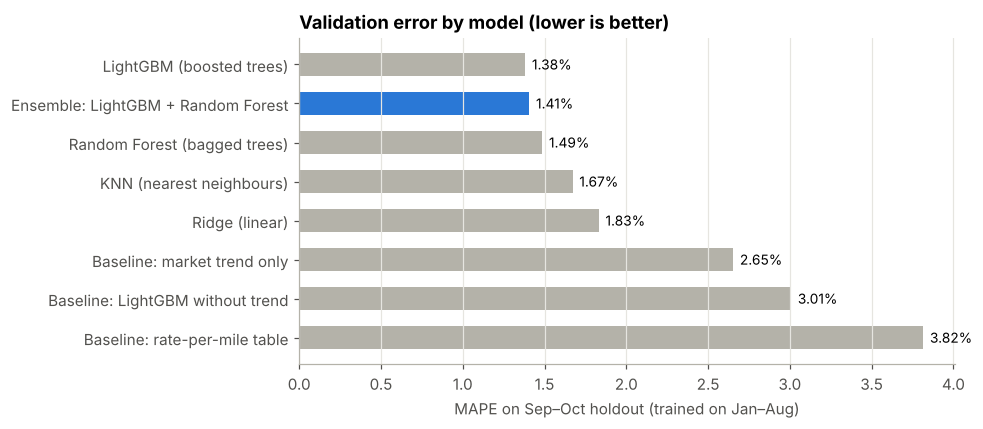

,1: Jul-Aug,2: Aug-Sep,3: Sep-Oct,avg MAPE_%,avg MAE_$,avg bias_%
model,,,,,,
Ensemble: LightGBM + Random Forest,1.830,1.479,1.408,1.572,37.351,0.567
Random Forest (bagged trees),1.851,1.496,1.487,1.611,37.924,0.544
LightGBM (boosted trees),1.889,1.570,1.383,1.614,38.475,0.589
KNN (nearest neighbours),1.979,1.687,1.673,1.780,41.807,0.525
Ridge (linear),2.116,1.802,1.832,1.917,44.541,0.495
Baseline: market trend only,2.795,2.645,2.655,2.698,57.410,0.532
Baseline: LightGBM without trend,3.041,2.995,3.009,3.015,67.639,-2.394
Baseline: rate-per-mile table,3.972,3.828,3.817,3.872,84.241,-0.425


In [26]:
BEST = combos.iloc[0]
print("Selected ensemble:", BEST.ensemble, f"(avg MAPE {BEST['avg MAPE_%']:.3f}%)")
for i in range(len(FOLDS)):
    record("Ensemble: " + BEST.ensemble, i, np.exp(np.mean([np.log(PRED[(n, i)]) for n in BEST.members], axis=0)))

# Chart: all models on the primary holdout (fold 3)
r = pd.DataFrame(results)
r3 = r[r.fold == FOLD_NAMES[2]].set_index("model")["MAPE_%"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(r3.index, r3.values, color=[BLUE if m.startswith("Ensemble") else GRAY for m in r3.index], height=0.6)
for y, v in enumerate(r3.values):
    ax.text(v + 0.04, y, f"{v:.2f}%", va="center", fontsize=9)
ax.grid(axis="y", visible=False)
ax.set(xlabel="MAPE on Sep–Oct holdout (trained on Jan–Aug)", title="Validation error by model (lower is better)")
savefig(fig, "model_comparison.png")
plt.show()
table()

**Decision:** the final model is an **equal-weight average of LightGBM and Random Forest**, both on top of the market-trend baseline.

- It has the lowest error averaged over the three folds. On the Sep–Oct fold LightGBM alone is very slightly better, but across all three periods the ensemble is more consistent.
- Adding Ridge or KNN makes the ensemble *worse*. Diversity only helps when the extra members are also accurate.
- We keep equal weights rather than tuning them. Tuning weights on three folds would risk overfitting the validation set for a very small gain.

## 6. Evaluating the chosen model on the primary holdout (Sep–Oct)

### Why there is no confusion matrix

A confusion matrix counts correct and incorrect class predictions, so it needs categories. Here we predict a continuous dollar amount. The regression equivalents are below: error tables, predicted-vs-actual and residual plots, and error broken down by price band. For readers who think in categories, the final table bins rates into price bands and shows how often the predicted band matches the actual band. That is the closest analogue, but it is an illustration rather than the real metric.

In [27]:
FINAL_NAME = "Ensemble: " + BEST.ensemble
tr3, te3, te3_clean = FOLD_CACHE[2]
hold = te3_clean.copy()
hold["predicted_rate"] = PRED[(FINAL_NAME, 2)]
hold["error"] = hold.predicted_rate - hold.posted_rate
hold["abs_pct_error"] = hold.error.abs() / hold.posted_rate * 100

summary = pd.DataFrame({
    "Clean labels (model target)": metrics(hold.posted_rate, hold.predicted_rate),
}).T
# Same model scored against ALL Sep–Oct labels, including the corrupted ones
p_all = []
M_all = build_matrices(tr3, te3)
for n in BEST.members:
    model, cols = make_family_models()[n]
    cols = cols or list(M_all["X_tr"].columns)
    model.fit(M_all["X_tr"][cols], M_all["resid"])
    p_all.append(M_all["base_te"] + model.predict(M_all["X_te"][cols]))
summary.loc["All labels incl. corrupted"] = metrics(te3.posted_rate, np.exp(np.mean(p_all, axis=0)))
summary["within ±2%"] = [(hold.abs_pct_error <= 2).mean() * 100, np.nan]
summary["within ±5%"] = [(hold.abs_pct_error <= 5).mean() * 100, np.nan]
summary.round(2)

,MAPE_%,MAE_$,RMSE_$,bias_%,within ±2%,within ±5%
Clean labels (model target),1.410,32.900,47.450,-0.420,74.760,99.490
All labels incl. corrupted,3.930,89.030,629.130,-0.420,NaN,NaN


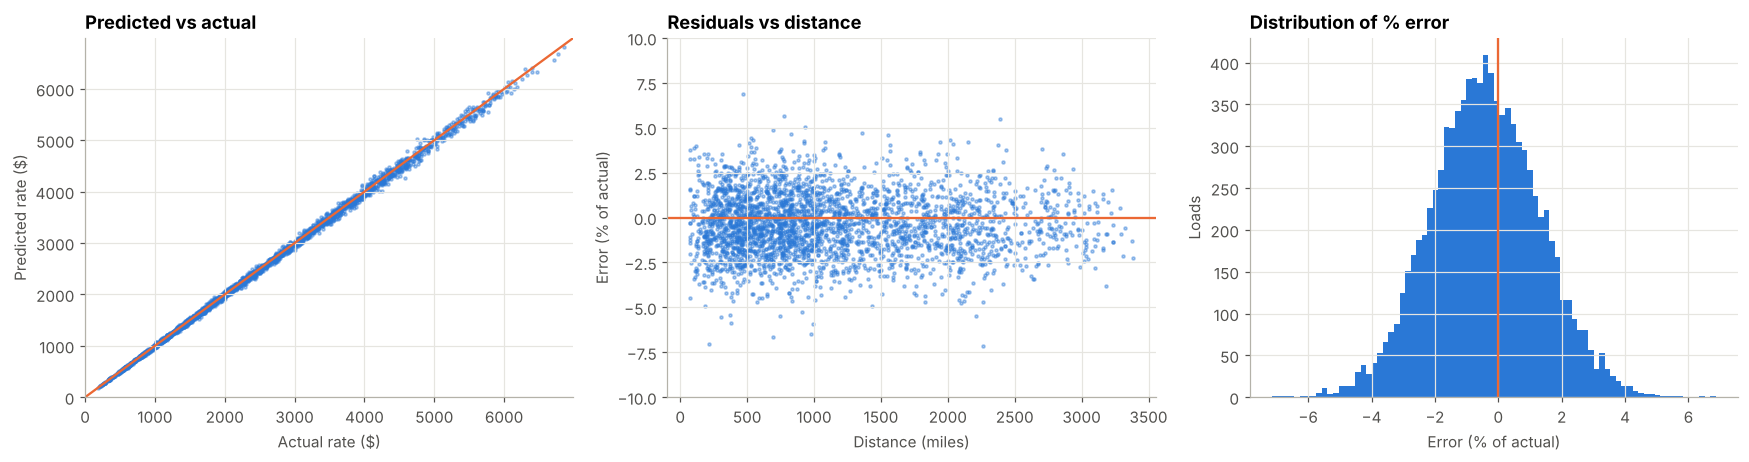

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
s = hold.sample(3000, random_state=SEED)
axes[0].scatter(s.posted_rate, s.predicted_rate, s=4, alpha=0.4, color=BLUE)
lim = [0, s.posted_rate.max() * 1.02]
axes[0].plot(lim, lim, color=ORANGE, lw=1.5)
axes[0].set(title="Predicted vs actual", xlabel="Actual rate ($)", ylabel="Predicted rate ($)", xlim=lim, ylim=lim)

axes[1].scatter(s.distance, s.error / s.posted_rate * 100, s=4, alpha=0.4, color=BLUE)
axes[1].axhline(0, color=ORANGE, lw=1.5)
axes[1].set(title="Residuals vs distance", xlabel="Distance (miles)", ylabel="Error (% of actual)", ylim=(-10, 10))

axes[2].hist((hold.error / hold.posted_rate * 100).clip(-10, 10), bins=80, color=BLUE)
axes[2].axvline(0, color=ORANGE, lw=1.5)
axes[2].set(title="Distribution of % error", xlabel="Error (% of actual)", ylabel="Loads")
savefig(fig, "holdout_diagnostics.png")
plt.show()

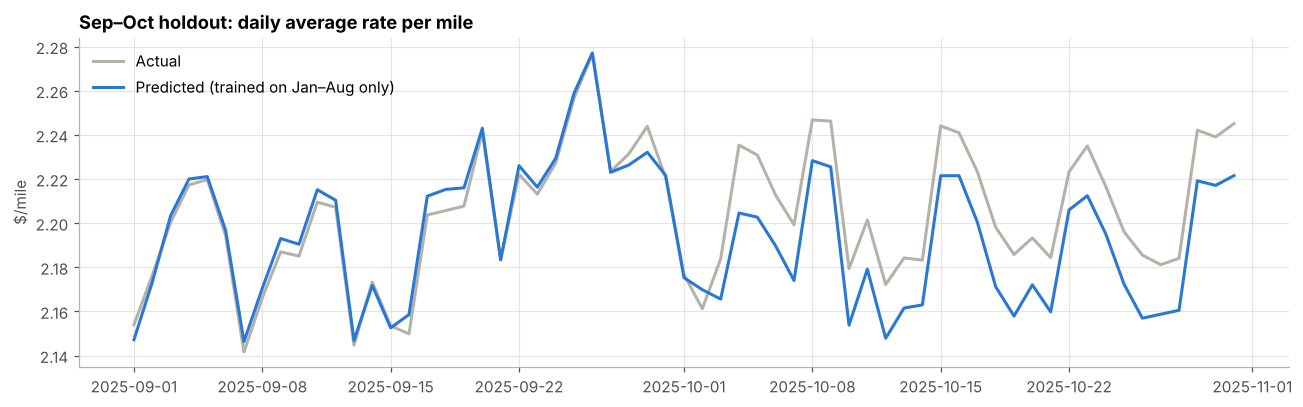

In [29]:
d = hold.assign(actual=hold.posted_rate / hold.distance, predicted=hold.predicted_rate / hold.distance).groupby("date")[["actual", "predicted"]].mean()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(d.index, d.actual, color=GRAY, lw=2, label="Actual")
ax.plot(d.index, d.predicted, color=BLUE, lw=2, label="Predicted (trained on Jan–Aug only)")
ax.set(title="Sep–Oct holdout: daily average rate per mile", ylabel="$/mile")
ax.legend(frameon=False, loc="upper left")
savefig(fig, "holdout_daily.png")
plt.show()

In [30]:
def breakdown(by):
    return hold.groupby(by, observed=True).apply(
        lambda g: pd.Series({**metrics(g.posted_rate, g.predicted_rate), "loads": len(g)}), include_groups=False).round(2)

seen_lanes = set(zip(tr3.pickup, tr3.delivery))
hold["lane_seen_in_training"] = [lane in seen_lanes for lane in zip(hold.pickup, hold.delivery)]
print("By equipment"); display(breakdown("equipment"))
print("By month (error grows with forecast horizon)"); display(breakdown(hold.date.dt.month.rename("month")))
print("By distance band"); display(breakdown(pd.cut(hold.distance, [0, 250, 500, 1000, 2000, 4000]).rename("distance")))

By equipment


,MAPE_%,MAE_$,RMSE_$,bias_%,loads
equipment,,,,,
Dry Van,1.400,30.920,43.960,-0.330,"5,275.000"
Flatbed,1.510,36.750,53.650,-0.810,"1,746.000"
Reefer,1.340,34.490,50.020,-0.360,"2,358.000"


By month (error grows with forecast horizon)


,MAPE_%,MAE_$,RMSE_$,bias_%,loads
month,,,,,
9,1.300,30.540,44.150,0.130,"4,606.000"
10,1.510,35.190,50.430,-0.960,"4,773.000"


By distance band


,MAPE_%,MAE_$,RMSE_$,bias_%,loads
distance,,,,,
"(0, 250]",1.550,7.430,9.630,-0.560,544.000
"(250, 500]",1.410,13.310,16.800,-0.500,"1,511.000"
"(500, 1000]",1.410,23.300,29.770,-0.400,"2,927.000"
"(1000, 2000]",1.410,41.500,52.670,-0.410,"2,884.000"
"(2000, 4000]",1.350,63.830,81.490,-0.360,"1,513.000"


In [31]:
PRICE_BANDS = [0, 500, 1000, 2000, 3500, np.inf]
BAND_LABELS = ["<$500", "$500-1k", "$1k-2k", "$2k-3.5k", ">$3.5k"]
hold["actual_band"] = pd.cut(hold.posted_rate, PRICE_BANDS, labels=BAND_LABELS)
hold["predicted_band"] = pd.cut(hold.predicted_rate, PRICE_BANDS, labels=BAND_LABELS)

print("Error by actual price band")
display(breakdown("actual_band"))

band_matrix = pd.crosstab(hold.actual_band, hold.predicted_band, rownames=["actual band"], colnames=["predicted band"])
print(f"Price-band agreement (illustration only, not a classification metric): "
      f"{(hold.actual_band == hold.predicted_band).mean():.1%} of loads land in the right band.")
print("Off-diagonal loads sit right next to a band boundary: their median % error is",
      f"{hold.loc[hold.actual_band != hold.predicted_band, 'abs_pct_error'].median():.2f}%")
band_matrix

Error by actual price band


,MAPE_%,MAE_$,RMSE_$,bias_%,loads
actual_band,,,,,
<$500,1.530,5.540,6.930,-0.280,264.000
$500-1k,1.420,10.940,13.870,-0.510,"1,220.000"
$1k-2k,1.420,21.040,26.800,-0.380,"3,066.000"
$2k-3.5k,1.400,36.700,46.120,-0.430,"2,709.000"
>$3.5k,1.380,61.260,78.030,-0.450,"2,120.000"


Price-band agreement (illustration only, not a classification metric): 97.9% of loads land in the right band.
Off-diagonal loads sit right next to a band boundary: their median % error is 2.17%


predicted band,<$500,$500-1k,$1k-2k,$2k-3.5k,>$3.5k
actual band,,,,,
<$500,261,3,0,0,0
$500-1k,13,1192,15,0,0
$1k-2k,0,31,3013,22,0
$2k-3.5k,0,0,57,2633,19
>$3.5k,0,0,0,39,2081


### Robustness check: cities the model has never seen

12% of the loads to predict involve one of 8 cities absent from training. To estimate the error on those loads, we repeat the primary split but also delete every training load touching 8 randomly chosen cities, then score test loads involving those cities. We repeat this with 3 random city sets.

In [32]:
def fit_ensemble(tr):
    """Fit the chosen ensemble (trend baseline + averaged family models). Returns a predict function."""
    M = build_matrices(tr, tr.iloc[:1])
    enc_cols = list(M["X_tr"].columns)
    members = []
    for n in BEST.members:
        model, cols = make_family_models()[n]
        cols = cols or enc_cols
        members.append((model.fit(M["X_tr"][cols], M["resid"]), cols))
    trend = M["trend"]
    enc = TargetEncoder()
    enc.fit_transform(tr, np.log(tr.posted_rate / tr.distance))

    def predict(df):
        X = base_features(df).join(enc.transform(df))[enc_cols]
        return np.exp(trend.predict_log(df) + np.mean([m.predict(X[c]) for m, c in members], axis=0))
    return predict

cities = np.array(sorted(train_cities))
rows = []
for seed in range(3):
    held_out = set(np.random.default_rng(seed).choice(cities, 8, replace=False))
    touches_tr = tr3.pickup.isin(held_out) | tr3.delivery.isin(held_out)
    touches_te = te3_clean.pickup.isin(held_out) | te3_clean.delivery.isin(held_out)
    p = fit_ensemble(tr3[~touches_tr])(te3_clean)
    rows.append({"run": seed, "loads touching held-out cities": touches_te.sum(),
                 "MAPE unseen cities": metrics(te3_clean.posted_rate[touches_te], p[touches_te.to_numpy()])["MAPE_%"],
                 "MAPE known cities": metrics(te3_clean.posted_rate[~touches_te], p[~touches_te.to_numpy()])["MAPE_%"]})
unseen_check = pd.DataFrame(rows)
display(unseen_check.round(2))
print(unseen_check[["MAPE unseen cities", "MAPE known cities"]].mean().round(2).to_dict())

,run,loads touching held-out cities,MAPE unseen cities,MAPE known cities
0,0,1718,1.920,1.410
1,1,2246,1.610,1.420
2,2,2124,1.650,1.410


{'MAPE unseen cities': 1.73, 'MAPE known cities': 1.41}


**Evaluation summary**

- On clean labels the ensemble is off by 1.41% on average ($33). 75% of loads are within ±2% and 99.5% within ±5%. Errors are balanced across equipment types and distance bands, and show no pattern against distance.
- Error grows with the forecast horizon (the second test month is worse than the first). December will be the hardest month to predict.
- On new cities the error rises moderately (about 1.7% vs 1.4%) rather than breaking down, because coordinates and distance carry most of the signal.
- **Against all labels, including corrupted ones, the measured error is much higher (3.9% / $89).** That gap comes almost entirely from the 1.4% of loads whose recorded rate is wrong by 2–5×. If the final answer key contains similar corruption, scores will look worse than the model really is.

## 7. Final model, submission files and the December chart

Retrain the chosen ensemble on **all clean January–October loads**, then predict:
1. every load in `validation.csv` → `validation_predictions.csv`
2. the 31 December rows → fill `data/december_chart_inputs.csv`

The December inputs have no `market_index` or `quote_signal`. Because `market_index` is a daily market level, each December date takes the mean `market_index` of the ~200 validation loads on that same date, and `quote_signal` takes that date's median. These are features of the loads being scored, not labels.

In [33]:
final_train = train[~train.label_outlier]
final_predict = fit_ensemble(final_train)
final_trend = MarketTrend().fit(final_train, np.log(final_train.posted_rate))
print(f"Trained on {len(final_train):,} clean loads.", final_trend.summary())

val_pred = pd.Series(final_predict(val).round(2), index=val.load_id)
submission = template[["load_id"]].copy()
submission["predicted_rate"] = submission.load_id.map(val_pred)
assert len(submission) == 12_000 and submission.predicted_rate.notna().all() and (submission.predicted_rate > 0).all()
submission.to_csv("validation_predictions.csv", index=False)
print("Wrote validation_predictions.csv")
submission.predicted_rate.describe()

Trained on 47,323 clean loads. {'monthly trend': '0.60%', '+1 market_index': '15.3%', 'quarter-end uplift (last day)': '4.07%'}


Wrote validation_predictions.csv


count   12,000.000
mean     2,395.126
std      1,384.643
min        196.140
25%      1,289.613
50%      2,071.090
75%      3,399.712
max      7,008.810
Name: predicted_rate, dtype: float64

In [34]:
city_coords = pd.concat([
    d[[f"{side}", f"{side}_lat", f"{side}_lon"]].set_axis(["city", "lat", "lon"], axis=1)
    for d in (train_raw, val_raw) for side in ("pickup", "delivery")
]).groupby("city")[["lat", "lon"]].median()

dec = december_template.copy()
dec["date"] = pd.to_datetime(dec.date)
for side in ("pickup", "delivery"):
    dec[f"{side}_lat"] = dec[side].map(city_coords.lat)
    dec[f"{side}_lon"] = dec[side].map(city_coords.lon)
dec["market_index"] = dec.date.map(DAILY_MARKET)
dec["quote_signal"] = dec.date.map(val_raw.groupby("date").quote_signal.median())
dec = clean(dec)

december_out = december_template.copy()
december_out["predicted_rate"] = final_predict(dec).round(2)
december_out.to_csv(DATA / "december_chart_inputs.csv", index=False)
print(f"December predictions: ${december_out.predicted_rate.min():,.2f} - ${december_out.predicted_rate.max():,.2f}")

lane = train[(train.pickup == "Lexington") & (train.delivery == "Fort Wayne") & (train.equipment == "Dry Van") & ~train.label_outlier]
print(f"Sanity check: historical Dry Van loads on this lane: ${lane.posted_rate.min():,.0f}-${lane.posted_rate.max():,.0f}, "
      f"median ${(lane.posted_rate / lane.distance).median():.2f}/mile; December prediction "
      f"${(december_out.predicted_rate / 360).min():.2f}-${(december_out.predicted_rate / 360).max():.2f}/mile")
december_out.assign(market_index=dec.market_index.round(3))

December predictions: $828.07 - $866.68
Sanity check: historical Dry Van loads on this lane: $758-$934, median $2.23/mile; December prediction $2.30-$2.41/mile


,pickup,delivery,distance,equipment,weight,date,predicted_rate,market_index
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,828.070,0.835
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,837.170,0.915
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,845.180,0.994
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,847.820,1.024
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,842.880,0.975
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,835.380,0.889
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,830.030,0.831
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,831.570,0.840
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,840.600,0.917
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,848.310,0.999


Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.



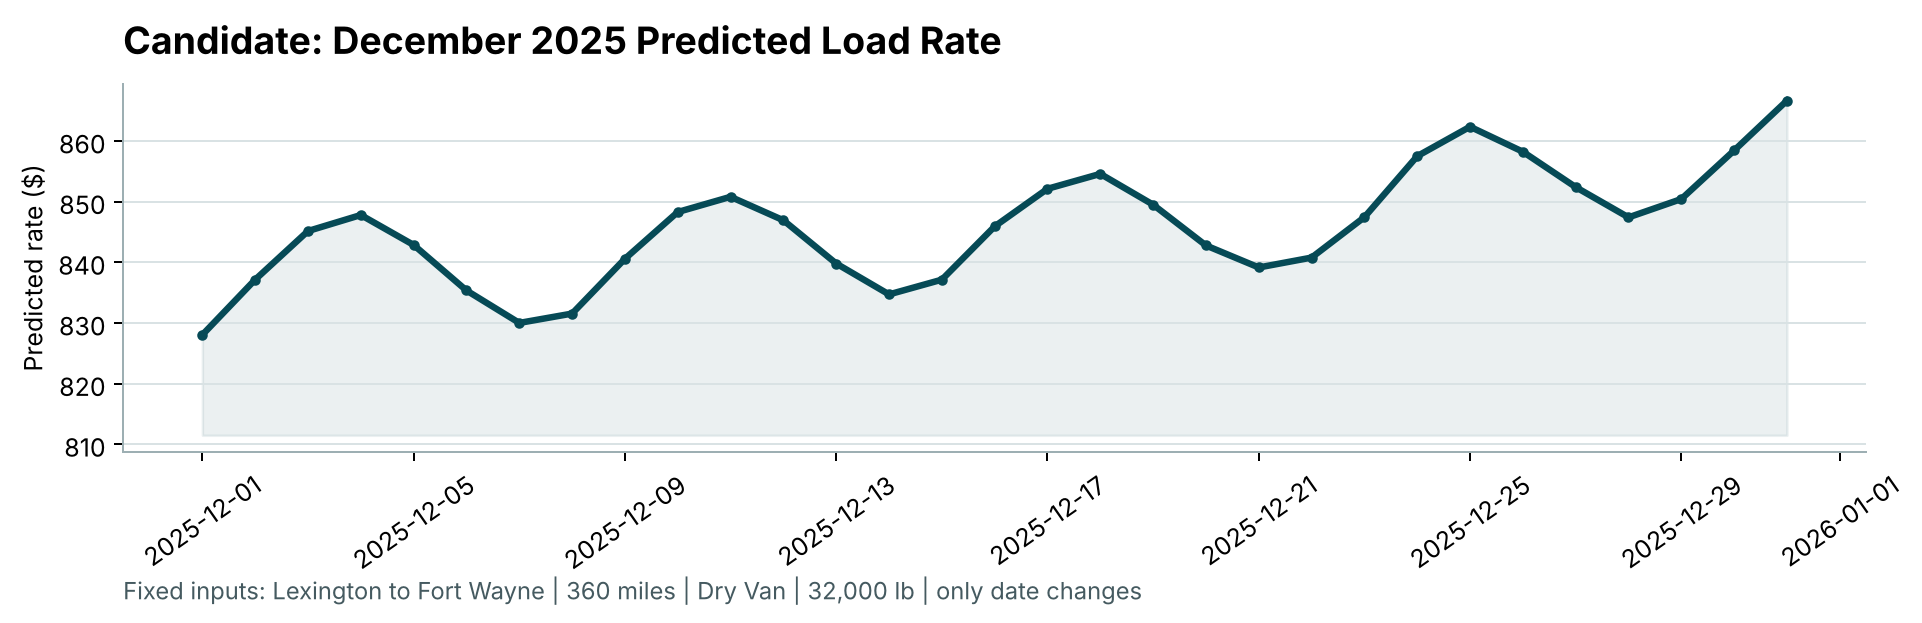

In [35]:
result = subprocess.run([sys.executable, "score.py", "--predictions", "validation_predictions.csv",
                         "--december-predictions", str(DATA / "december_chart_inputs.csv")],
                        capture_output=True, text=True)
print(result.stdout or result.stderr)
display(Image("scorer_results/candidate_december.png", width=900))

**Reading the December chart**

- **Weekly waves** come from the daily market index, which follows a weekly cycle in both the training data and the December validation loads.
- **The upward drift through the month** is the quarter-end surge seen in March, June and September, plus the small monthly trend.
- The level is consistent with the lane's history: recent Dry Van loads ran about $2.23 per mile. December sits slightly above that because of the upward trend and the quarter-end surge.

## 8. Conclusions and limitations

- **Validation:** time-based splits that mirror the real task (train on the past, predict the next two months), with a Sep–Oct primary holdout.
- **Model:** a market-trend baseline (linear) plus an equal-weight average of LightGBM and Random Forest, chosen over Ridge, KNN, and every other combination by average error across three time folds.
- **Biggest wins:** handling the trend and quarter-end surge explicitly (standard LightGBM underpredicts future months by 2–3%), and removing the 677 corrupted labels from training.
- **Risks:** the trend is extrapolated two months ahead; December may have year-end effects that no training month shows; and corrupted labels in the answer key would inflate measured error.
- **Next steps with more time:** prediction intervals (quantile models), re-estimating the trend as new data arrives, and monitoring the quarter-end effect.